<a href="https://colab.research.google.com/github/ThePretelR/cassava-disease-model-comparison/blob/main/notebooks/06_evaluacion_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06 — Evaluación final de E0–E3
Evaluación única sobre las 1.874 imágenes de prueba depuradas. Sin entrenamiento ni ajuste de hiperparámetros. Comparación primaria E1–E3 y secundaria E1–E2.

## 1. Entorno y configuración

In [4]:
%pip -q install tensorflow-datasets importlib_resources psutil

In [5]:
import os, gc, time, hashlib, json, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
CLASS_NAMES = ["cbb", "cbsd", "cgm", "cmd", "healthy"]
MODELS = ["E0", "E1", "E2", "E3"]
OUTPUT_DIR = Path("results/evaluacion_final")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)
print(tf.__version__, tf.config.list_physical_devices("GPU"))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Carga de checkpoints


In [6]:
from google.colab import files

MODEL_DIR = Path("/content")

RUTAS = {
    m: MODEL_DIR / f"mejor_modelo_{m.lower()}.keras"
    for m in MODELS
}

faltantes = [
    str(p) for p in RUTAS.values()
    if not p.is_file()
]

if faltantes:
    raise FileNotFoundError(
        "Archivos faltantes: " + ", ".join(faltantes)
    )

for nombre, ruta in RUTAS.items():
    print(f"{nombre}: {ruta} | {ruta.stat().st_size / 1024**2:.2f} MiB")

E0: /content/mejor_modelo_e0.keras | 1.31 MiB
E1: /content/mejor_modelo_e1.keras | 11.07 MiB
E2: /content/mejor_modelo_e2.keras | 20.18 MiB
E3: /content/mejor_modelo_e3.keras | 93.63 MiB


## 3. Partición de prueba e integridad

In [7]:
URL = "https://raw.githubusercontent.com/ThePretelR/cassava-disease-model-comparison/main/results/eda/manifiesto_final_conservados.csv"
manifest = pd.read_csv(URL)
assert len(manifest) == 9361
assert not manifest.duplicated(["particion", "indice"]).any()
prueba = manifest.loc[manifest.particion == "test"].sort_values("indice")
assert len(prueba) == 1874
raw, info = tfds.load("cassava:0.1.0", split="test", as_supervised=True, with_info=True, shuffle_files=False)
assert list(info.features["label"].names) == CLASS_NAMES
esperados = prueba.set_index("indice")
indices = set(esperados.index.astype(int))
assert min(indices) >= 0 and max(indices) < 1885
verificados = 0
for i, (img, y) in enumerate(raw):
    if i in indices:
        a = img.numpy()
        h = hashlib.sha256(str(a.shape).encode("utf-8") + a.tobytes()).hexdigest()
        assert h == esperados.loc[i, "hash"], f"Hash distinto: {i}"
        assert CLASS_NAMES[int(y.numpy())] == esperados.loc[i, "clase"]
        verificados += 1
assert verificados == 1874
mascara = tf.constant([i in indices for i in range(1885)])
test = (raw.enumerate().filter(lambda i, d: tf.gather(mascara, i))
        .map(lambda i, d: d, num_parallel_calls=1)
        .apply(tf.data.experimental.assert_cardinality(1874)))
print("Imágenes verificadas:", verificados)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-test.tfrecord-[0-9][0-9][0-9][0-9]…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cassava/incomplete.HBRPOI_0.1.0/cassava-validation.tfrecord-[0-9][0-9][0-9…

Dataset cassava downloaded and prepared to /root/tensorflow_datasets/cassava/0.1.0. Subsequent calls will reuse this data.
Imágenes verificadas: 1874


## 4. Pipeline de evaluación
E0 recibe píxeles en [0,1]. E1–E3 reciben [0,255] porque sus checkpoints incorporan el preprocesamiento correspondiente.

In [8]:
def preparar(img, y):
    return tf.cast(tf.image.resize(img, IMG_SIZE, method="bilinear"), tf.float32), tf.cast(y, tf.int32)
base_test = test.map(preparar, num_parallel_calls=2).batch(BATCH_SIZE).prefetch(1)
y_true = np.concatenate([y.numpy() for _, y in base_test])
assert len(y_true) == 1874
assert np.array_equal(y_true, prueba.clase.map(CLASS_NAMES.index).to_numpy())

def dataset_modelo(nombre):
    if nombre == "E0":
        return base_test.map(lambda x, y: (x / 255.0, y), num_parallel_calls=1)
    return base_test

## 5. Evaluación de los cuatro modelos
Se carga un modelo a la vez. El tiempo incluye el pipeline y la predicción por lotes, tras dos lotes de calentamiento. El tamaño de pesos excluye el optimizador; el tamaño del checkpoint lo incluye si fue guardado.

235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 37ms/step


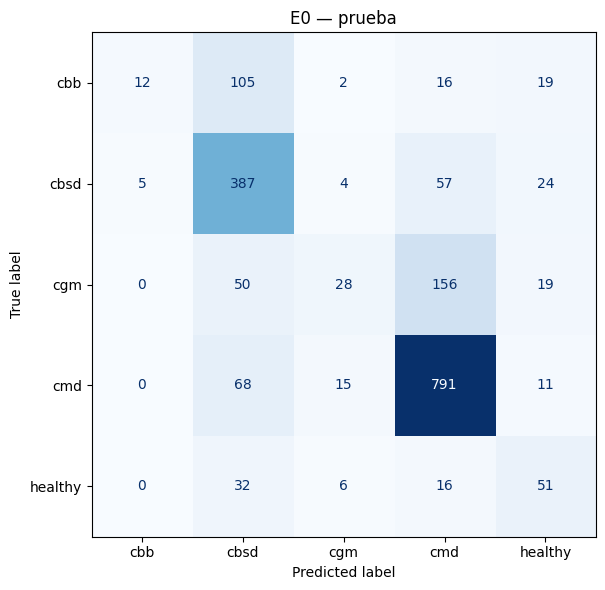

{'modelo': 'E0', 'accuracy': 0.6771611526147279, 'macro_f1': 0.4565604651960675, 'tiempo_entrenamiento_s': 495.674839109, 'epocas': 15, 'tiempo_acumulado_entrenamiento_s': 495.674839109, 'ms_inferencia_imagen': 4.818229557097074, 'parametros_totales': 110405, 'pesos_MiB': np.float64(0.4211616516113281), 'checkpoint_MiB': 1.308833122253418}
235/235 ━━━━━━━━━━━━━━━━━━━━ 19s 80ms/step


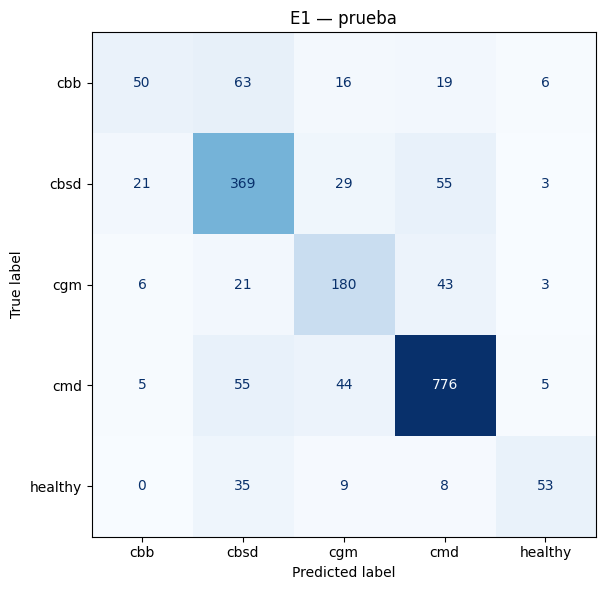

{'modelo': 'E1', 'accuracy': 0.7620064034151548, 'macro_f1': 0.6599839151558283, 'tiempo_entrenamiento_s': 286.504443499, 'epocas': 7, 'tiempo_acumulado_entrenamiento_s': 286.504443499, 'ms_inferencia_imagen': 10.092262981323396, 'parametros_totales': 2422597, 'pesos_MiB': np.float64(9.241474151611328), 'checkpoint_MiB': 11.066140174865723}
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step


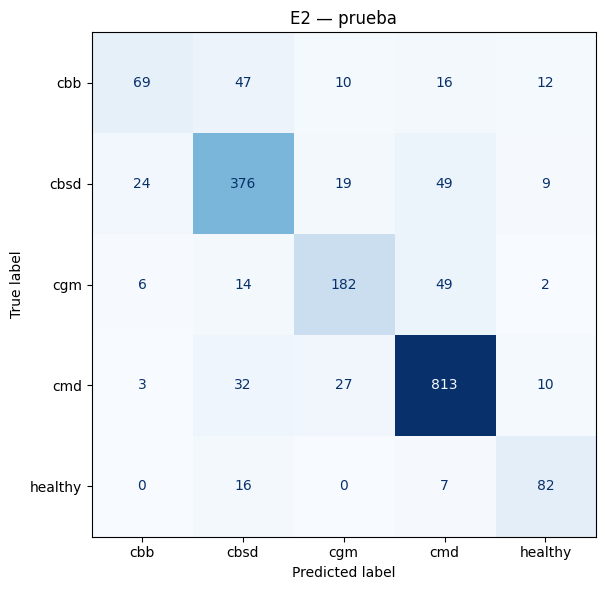

{'modelo': 'E2', 'accuracy': 0.8121664887940235, 'macro_f1': 0.7402927537385939, 'tiempo_entrenamiento_s': 228.55275893099997, 'epocas': 7, 'tiempo_acumulado_entrenamiento_s': 515.05720243, 'ms_inferencia_imagen': 5.480118855389553, 'parametros_totales': 2422597, 'pesos_MiB': np.float64(9.241474151611328), 'checkpoint_MiB': 20.181703567504883}
235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 88ms/step


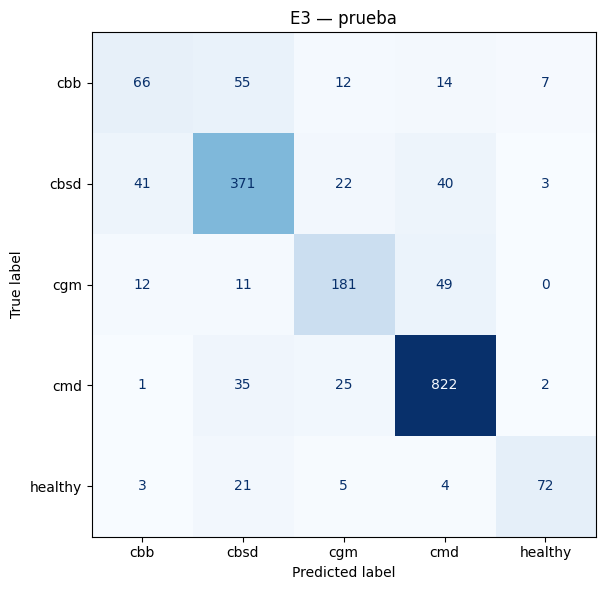

{'modelo': 'E3', 'accuracy': 0.8068303094983992, 'macro_f1': 0.7273159192617483, 'tiempo_entrenamiento_s': 294.627189, 'epocas': 7, 'tiempo_acumulado_entrenamiento_s': 294.627189, 'ms_inferencia_imagen': 11.109394118996779, 'parametros_totales': 23850641, 'pesos_MiB': np.float64(90.98297500610352), 'checkpoint_MiB': 93.6260347366333}


In [9]:
tiempos = {"E0": 495.674839109, "E1": 286.504443499, "E2": 228.55275893099997, "E3": 294.627189}
epocas = {"E0": 15, "E1": 7, "E2": 7, "E3": 7}
filas, reportes = [], []
for nombre in MODELS:
    tf.keras.backend.clear_session()
    modelo = tf.keras.models.load_model(RUTAS[nombre], compile=False)
    assert tuple(modelo.input_shape[1:]) == (224, 224, 3)
    assert modelo.output_shape[-1] == 5
    ds = dataset_modelo(nombre)
    modelo.predict(ds.take(2), verbose=0)
    inicio = time.perf_counter()
    probs = modelo.predict(ds, verbose=1)
    segundos = time.perf_counter() - inicio
    assert probs.shape == (1874, 5) and np.isfinite(probs).all()
    np.testing.assert_allclose(probs.sum(axis=1), 1, atol=1e-4)
    pred = probs.argmax(axis=1)
    reporte = pd.DataFrame(classification_report(y_true, pred, labels=range(5), target_names=CLASS_NAMES, output_dict=True, zero_division=0)).T
    reporte.to_csv(OUTPUT_DIR / f"reporte_{nombre.lower()}.csv")
    por_clase = reporte.loc[CLASS_NAMES].copy()
    por_clase.insert(0, "modelo", nombre)
    reportes.append(por_clase.reset_index(names="clase"))
    matriz = confusion_matrix(y_true, pred, labels=range(5))
    pd.DataFrame(matriz, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUTPUT_DIR / f"matriz_{nombre.lower()}.csv")
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(matriz, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{nombre} — prueba")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"matriz_{nombre.lower()}.png", dpi=180)
    plt.show()
    plt.close(fig)
    datos = pd.DataFrame({"indice_original": prueba.indice.to_numpy(), "real": y_true, "prediccion": pred, "confianza": probs.max(axis=1)})
    for j, clase in enumerate(CLASS_NAMES):
        datos[f"prob_{clase}"] = probs[:, j]
    datos.to_csv(OUTPUT_DIR / f"predicciones_{nombre.lower()}.csv", index=False)
    filas.append({"modelo": nombre, "accuracy": accuracy_score(y_true, pred),
                  "macro_f1": f1_score(y_true, pred, labels=range(5), average="macro", zero_division=0),
                  "tiempo_entrenamiento_s": tiempos[nombre], "epocas": epocas[nombre],
                  "tiempo_acumulado_entrenamiento_s": tiempos[nombre] + (tiempos["E1"] if nombre == "E2" else 0),
                  "ms_inferencia_imagen": segundos / len(y_true) * 1000,
                  "parametros_totales": modelo.count_params(),
                  "pesos_MiB": sum(np.prod(w.shape) * tf.as_dtype(w.dtype).size for w in modelo.weights) / 1024**2,
                  "checkpoint_MiB": RUTAS[nombre].stat().st_size / 1024**2})
    print(filas[-1])
    del modelo, ds, probs, pred
    gc.collect()
    tf.keras.backend.clear_session()

## 6. Tabla consolidada y comparaciones

In [10]:
tabla = pd.DataFrame(filas).set_index("modelo")
clases = pd.concat(reportes, ignore_index=True)
tabla.to_csv(OUTPUT_DIR / "tabla_consolidada.csv")
clases.to_csv(OUTPUT_DIR / "metricas_por_clase.csv", index=False)
display(tabla.round(4))
comparaciones = pd.DataFrame([{"comparacion": f"{b} - {a}", "delta_macro_f1": tabla.loc[b,"macro_f1"] - tabla.loc[a,"macro_f1"], "delta_accuracy": tabla.loc[b,"accuracy"] - tabla.loc[a,"accuracy"]} for a,b in [("E1","E3"),("E1","E2"),("E0","E1")]])
comparaciones.to_csv(OUTPUT_DIR / "comparaciones.csv", index=False)
display(comparaciones)

,accuracy,macro_f1,tiempo_entrenamiento_s,epocas,tiempo_acumulado_entrenamiento_s,ms_inferencia_imagen,parametros_totales,pesos_MiB,checkpoint_MiB
modelo,,,,,,,,,
E0,0.6772,0.4566,495.6748,15,495.6748,4.8182,110405,0.4212,1.3088
E1,0.7620,0.6600,286.5044,7,286.5044,10.0923,2422597,9.2415,11.0661
E2,0.8122,0.7403,228.5528,7,515.0572,5.4801,2422597,9.2415,20.1817
E3,0.8068,0.7273,294.6272,7,294.6272,11.1094,23850641,90.9830,93.6260


,comparacion,delta_macro_f1,delta_accuracy
0,E3 - E1,0.067332,0.044824
1,E2 - E1,0.080309,0.050160
2,E1 - E0,0.203423,0.084845


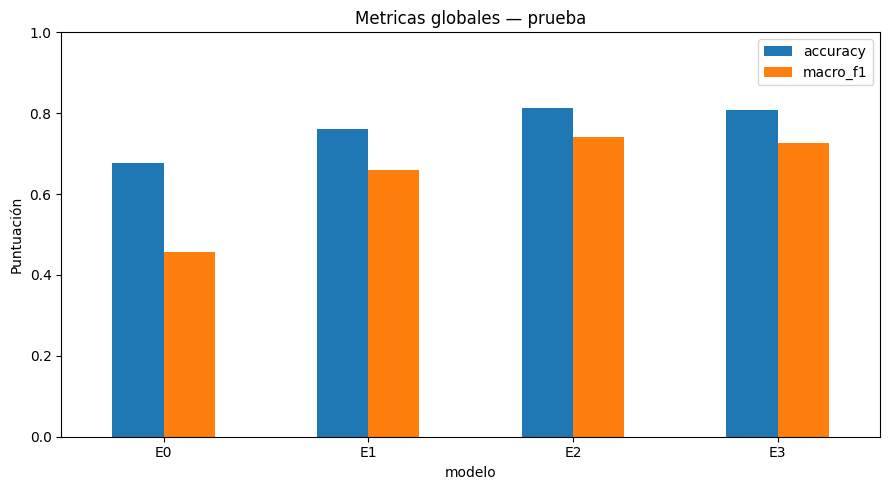

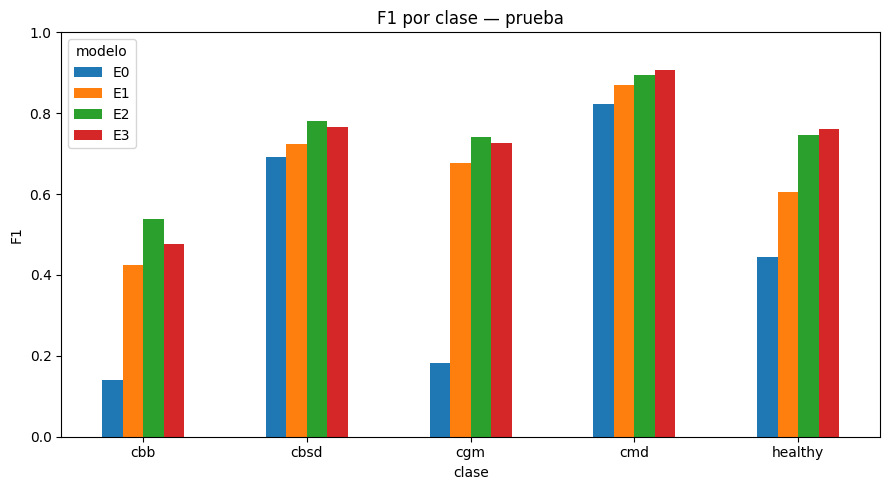

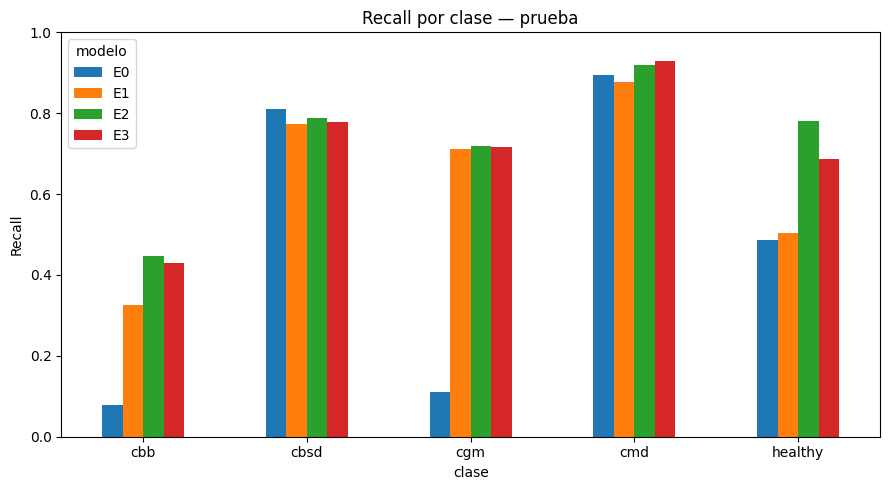

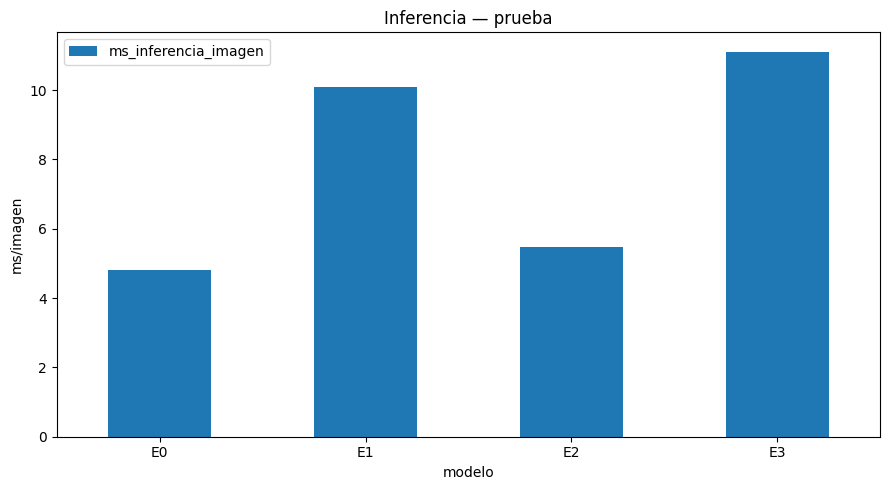

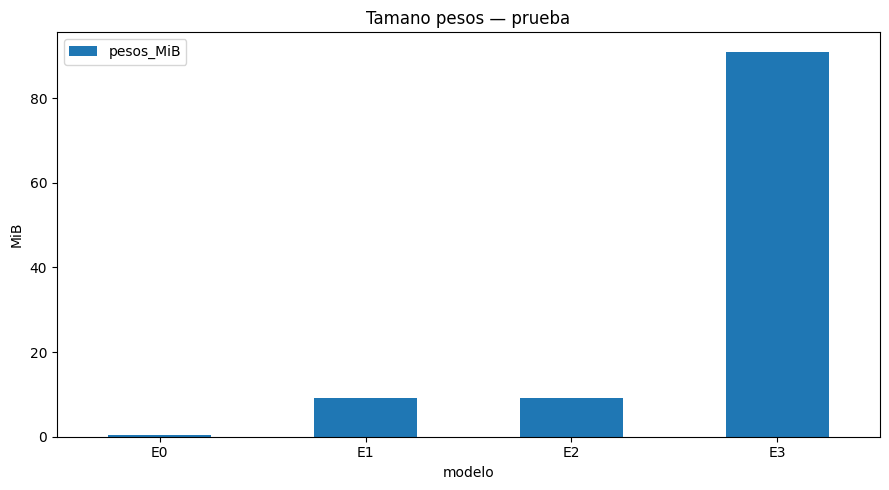

In [11]:
for nombre, datos, ylabel in [
    ("metricas_globales", tabla[["accuracy", "macro_f1"]], "Puntuación"),
    ("f1_por_clase", clases.pivot(index="clase", columns="modelo", values="f1-score").reindex(CLASS_NAMES), "F1"),
    ("recall_por_clase", clases.pivot(index="clase", columns="modelo", values="recall").reindex(CLASS_NAMES), "Recall"),
    ("inferencia", tabla[["ms_inferencia_imagen"]], "ms/imagen"),
    ("tamano_pesos", tabla[["pesos_MiB"]], "MiB")]:
    ax = datos.plot.bar(figsize=(9, 5), rot=0)
    ax.set_ylabel(ylabel)
    if nombre in ("metricas_globales", "f1_por_clase", "recall_por_clase"):
        ax.set_ylim(0, 1)
    ax.set_title(nombre.replace("_", " ").capitalize() + " — prueba")
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{nombre}.png", dpi=180)
    plt.show()
    plt.close(fig)